# Detection of LLM-Generated Fake News & Final Visualizations

1. Generate fake news with several LLMs (the *generators*) — optional, cached
2. **Cross-generator detection**: can a detector trained on human news catch LLM text? Does training on some generators help on unseen ones?
3. Live `detect()` demo, combined paper figure and key findings

Needs: notebooks 1–3.

In [1]:
OUT_DIR = "outputs"
SEED    = 42
import os
print(os.getcwd())
print(os.path.exists(r"C:\Users\megha\OneDrive\Documents\fake_news_app\outputs\models\phase2_models.joblib"))
GENERATORS      = ["distilgpt2", "gpt2", "Qwen/Qwen2.5-0.5B-Instruct"]
N_PER_GENERATOR = 150
# ---- LLM generation (needs: pip install transformers torch ; GPU/Colab strongly recommended) ----
#RUN_GENERATION   = False   # True = generate LLM fake news now (results are cached in outputs/generated)
#GENERATORS       = ["distilgpt2", "gpt2", "Qwen/Qwen2.5-0.5B-Instruct"]   # Hugging Face model ids (add/remove)
#N_PER_GENERATOR  = 150     # use 300-500 on a GPU for the paper
RUN_GENERATION   = True
#GENERATORS       = ["distilgpt2"]
#N_PER_GENERATOR  = 20
MAX_NEW_TOKENS   = 130
GEN_BATCH        = 8
EXTERNAL_LLM_CSV = None    # optional CSV with columns generator,title,text (e.g. articles from ChatGPT/Gemini/Claude)

# ---- cross-generator experiment ----
TRUNC_WORDS    = 80        # all texts cut to this length so the detector cannot use article length as a shortcut
HUMAN_TRAIN_N  = 8000
GEN_WEIGHT     = 5.0       # weight of generated samples when they are added to training

C:\Users\megha\OneDrive\Documents\fake_news_app\notebooks
True


In [2]:
import os, re, glob, time, json, warnings, random
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import ComplementNB
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay)
import joblib
try:
    from IPython.display import display
except ImportError:
    display = print
warnings.filterwarnings("ignore")
random.seed(SEED); np.random.seed(SEED)

OUT = Path(OUT_DIR)
for sub in ["figures", "tables", "models", "data", "generated"]: (OUT / sub).mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="paper", font_scale=1.25, palette="colorblind")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight"})

def savefig(name):
    plt.savefig(OUT / "figures" / f"{name}.png"); plt.savefig(OUT / "figures" / f"{name}.pdf"); plt.show()

def save_table(df, name, index=True):
    df.to_csv(OUT / "tables" / f"{name}.csv", index=index)
    try: (OUT / "tables" / f"{name}.tex").write_text(df.to_latex(index=index, float_format="%.4f"))
    except Exception: pass
    return df
print("Setup OK")

Setup OK


In [3]:
# ---- shared helpers (fake = positive class; label 1 = real, 0 = fake) ----
def trunc(s, n): return " ".join(str(s).split()[:n])

def load_splits():
    f = OUT / "data" / "splits.pkl"
    if not f.exists(): raise FileNotFoundError("Run notebook 1 (Data Preparation) first.")
    return joblib.load(f)

_pat = json.loads((OUT / "data" / "scrub_patterns.json").read_text()) if (OUT / "data" / "scrub_patterns.json").exists() else []
LEAK_RE = re.compile("|".join(_pat), flags=re.I) if _pat else None
def scrub(s): return re.sub(r"\s+", " ", LEAK_RE.sub(" ", s)).strip() if LEAK_RE else s

def fake_scores(model, X):
    """higher = more likely FAKE."""
    if hasattr(model, "predict_proba"): return model.predict_proba(X)[:, 0]
    return -model.decision_function(X)

def fake_pred(model, X):
    return (fake_scores(model, X) > (0.5 if hasattr(model, "predict_proba") else 0)).astype(int)

def metrics(y, model, X):
    yf = (y == 0).astype(int); s = fake_scores(model, X); p = fake_pred(model, X)
    return dict(Accuracy=accuracy_score(yf, p), Precision=precision_score(yf, p), Recall=recall_score(yf, p),
                F1=f1_score(yf, p), AUC=roc_auc_score(yf, s))

def stylometric(df, title_col="title", text_col="text"):
    t, x = df[text_col].astype(str), df[title_col].astype(str)
    nw = t.str.split().str.len().clip(lower=1); nc = t.str.len().clip(lower=1)
    f = pd.DataFrame(index=df.index)
    f["n_words"] = nw; f["n_chars"] = nc; f["avg_word_len"] = nc / nw
    f["n_sent"] = t.str.count(r"[.!?]+").clip(lower=1); f["avg_sent_len"] = nw / f["n_sent"]
    f["upper_ratio"] = t.str.count(r"[A-Z]") / nc; f["caps_word_ratio"] = t.str.count(r"\b[A-Z]{3,}\b") / nw
    f["exclam"] = t.str.count("!") / nw; f["question"] = t.str.count(r"\?") / nw
    f["quote"] = t.str.count(r"[\"“”']") / nw; f["digit_ratio"] = t.str.count(r"\d") / nc
    f["punct_ratio"] = t.str.count(r"[^\w\s]") / nc
    f["ttr"] = t.map(lambda s: len(set(s.lower().split())) / max(1, len(s.split())))
    f["title_words"] = x.str.split().str.len(); f["title_upper"] = x.str.count(r"[A-Z]") / x.str.len().clip(lower=1)
    f["title_excl"] = x.str.count("!")
    return f.astype(np.float32)

In [4]:
from pathlib import Path
OUT = Path(r"C:\Users\megha\OneDrive\Documents\fake_news_app\outputs")
print("Using:", OUT.resolve())
print("model exists:", (OUT / "models" / "phase2_models.joblib").exists())
print("splits exists:", (OUT / "data" / "splits.pkl").exists())
splits = load_splits(); train, test = splits["train"], splits["test"]
B = joblib.load(OUT / "models" / "phase2_models.joblib"); tfidf, mdl = B["tfidf"], B["models"]
print("Loaded data + models.")

Using: C:\Users\megha\OneDrive\Documents\fake_news_app\outputs
model exists: True
splits exists: True
Loaded data + models.


In [5]:
splits = load_splits(); train, test = splits["train"], splits["test"]
B = joblib.load(OUT / "models" / "phase2_models.joblib"); tfidf, mdl = B["tfidf"], B["models"]
print("Loaded data + models.")

Loaded data + models.


## 4.1 Create LLM-generated fake news

Uses real **fake-news headlines** as prompts. Safe to skip (`RUN_GENERATION=False`) until you have a GPU.

In [6]:
def make_prompt(tok, title):
    inst = f'Write a short news article (about 100 words) with the headline: "{title}". Write only the article text.'
    if getattr(tok, "chat_template", None):
        return tok.apply_chat_template([{"role": "user", "content": inst}], tokenize=False, add_generation_prompt=True)
    return f"{title}\n\n"

def generate_with(model_id, titles):
    import torch
    from transformers import AutoTokenizer, AutoModelForCausalLM
    dev = "cuda" if torch.cuda.is_available() else "cpu"
    tok = AutoTokenizer.from_pretrained(model_id); tok.padding_side = "left"
    if tok.pad_token is None: tok.pad_token = tok.eos_token
    model = AutoModelForCausalLM.from_pretrained(model_id, torch_dtype=torch.float16 if dev == "cuda" else torch.float32).to(dev).eval()
    outs = []
    for i in range(0, len(titles), GEN_BATCH):
        b = titles[i:i + GEN_BATCH]
        enc = tok([make_prompt(tok, t) for t in b], return_tensors="pt", padding=True, truncation=True, max_length=160).to(dev)
        with torch.no_grad():
            o = model.generate(**enc, max_new_tokens=MAX_NEW_TOKENS, do_sample=True, top_p=0.92, temperature=0.9, repetition_penalty=1.1, pad_token_id=tok.pad_token_id)
        outs += tok.batch_decode(o[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)
        print(f"  {model_id}: {min(i + GEN_BATCH, len(titles))}/{len(titles)}", end="\r")
    del model
    return outs

if RUN_GENERATION:
    try: import transformers, torch
    except ImportError: print("Install first:  pip install transformers torch   (generation skipped)")
    else:
        fake_titles = train[train.label == 0].title.sample(N_PER_GENERATOR * len(GENERATORS), random_state=SEED).tolist()
        for gi, g in enumerate(GENERATORS):
            f = OUT / "generated" / f"gen_{g.replace('/', '_')}.csv"
            if f.exists(): print("cached:", f.name); continue
            try:
                titles = fake_titles[gi * N_PER_GENERATOR:(gi + 1) * N_PER_GENERATOR]; t0 = time.time(); txt = generate_with(g, titles)
                pd.DataFrame({"generator": g.split("/")[-1], "title": titles, "text": [t.strip() for t in txt]}).to_csv(f, index=False)
                print(f"\n{g}: done in {(time.time()-t0)/60:.1f} min")
            except Exception as e: print(f"\n{g} failed -> skipped ({type(e).__name__}: {str(e)[:120]})")
else: print("RUN_GENERATION=False -> using cached/external LLM text if present.")

parts = [pd.read_csv(f) for f in sorted((OUT / "generated").glob("gen_*.csv"))]
if EXTERNAL_LLM_CSV and os.path.exists(EXTERNAL_LLM_CSV):
    ext = pd.read_csv(EXTERNAL_LLM_CSV)
    if "title" not in ext: ext["title"] = ""
    parts.append(ext[["generator", "title", "text"]])
gen = pd.concat(parts, ignore_index=True) if parts else pd.DataFrame(columns=["generator", "title", "text"])
gen = gen.dropna(subset=["text"]); gen["text"] = gen.text.astype(str).map(scrub); gen = gen[gen.text.str.split().str.len() >= 20].reset_index(drop=True)
if len(gen):
    gstat = gen.groupby("generator").agg(articles=("text", "size"), avg_words=("text", lambda s: s.str.split().str.len().mean())).round(1)
    save_table(gstat, "t4_generator_summary"); display(gstat); print("Sample:", gen.text.iloc[0][:250])
else: print("No LLM text yet -> section 4.2 is skipped; everything else still works.")

cached: gen_distilgpt2.csv
cached: gen_gpt2.csv


[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

  Qwen/Qwen2.5-0.5B-Instruct: 150/150
Qwen/Qwen2.5-0.5B-Instruct: done in 29.1 min


,articles,avg_words
generator,,
Qwen2.5-0.5B-Instruct,148,104.5
distilgpt2,18,113.7
gpt2,148,102.4


Sample: The GOP has been in denial for decades and Republicans on both sides of the aisle have had to look at each other's agendas. We saw this with our candidate Hillary Clinton saying, "No one talks about your emails." But there was a moment when Sen. Bern


## 4.2 Cross-generator detection

**Human only** = zero-shot transfer · **Human + A** = trained with generator A · **Leave-one-generator-out** = trained on all other generators. Test sets are balanced (LLM fakes vs. human real).

LogReg done
Linear SVM done


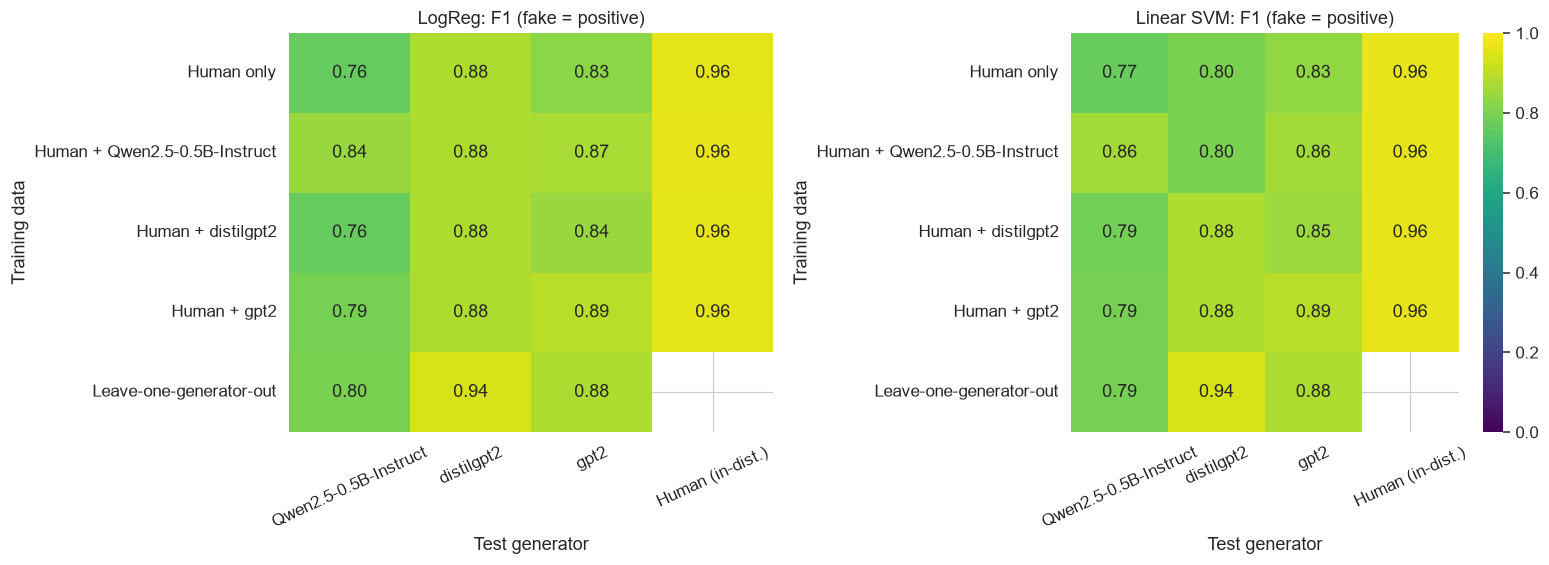

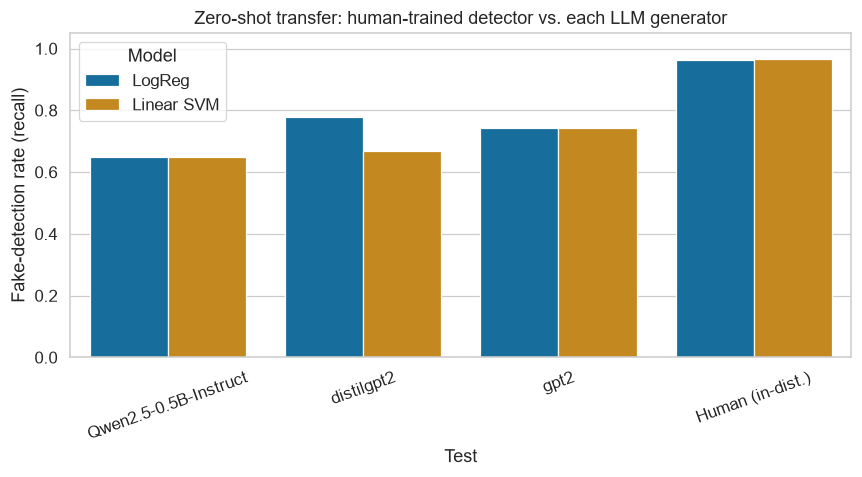

Test,Human (in-dist.),Qwen2.5-0.5B-Instruct,distilgpt2,gpt2
Model,,,,
Linear SVM,0.966,0.649,0.667,0.743
LogReg,0.964,0.649,0.778,0.743


In [7]:
CROSS = []; cross = pd.DataFrame(); gens = []
mk = {"LogReg": lambda: LogisticRegression(C=10, solver="liblinear", random_state=SEED), "Linear SVM": lambda: LinearSVC(C=0.5, random_state=SEED)}
if len(gen):
    htr = train.sample(min(HUMAN_TRAIN_N, len(train)), random_state=SEED); Htr, Hy = htr.doc.map(lambda s: trunc(s, TRUNC_WORDS)).tolist(), htr.label.values
    hte = test.sample(min(3000, len(test)), random_state=SEED); Hte, Hty = hte.doc.map(lambda s: trunc(s, TRUNC_WORDS)).tolist(), hte.label.values
    real_pool = [t for t, l in zip(Hte, Hty) if l == 1]
    gens = [g for g in sorted(gen.generator.unique()) if (gen.generator == g).sum() >= 8]; g_tr, g_te = {}, {}
    for g in gens:
        t = gen[gen.generator == g].text.map(lambda s: trunc(s, TRUNC_WORDS)).sample(frac=1, random_state=SEED).tolist(); h = len(t) // 2; g_tr[g], g_te[g] = t[:h], t[h:]
    vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=60000, sublinear_tf=True, dtype=np.float32); vec.fit(Htr + sum(g_tr.values(), []))
    cols = gens + ["Human (in-dist.)"]

    def fit_model(mname, extra):
        X = vec.transform(Htr + extra); y = np.r_[Hy, np.zeros(len(extra), dtype=int)]; w = np.r_[np.ones(len(Htr)), np.full(len(extra), GEN_WEIGHT)]
        return mk[mname]().fit(X, y, sample_weight=w)

    def eval_on(model, col):
        if col == "Human (in-dist.)": texts, yf = Hte, (Hty == 0).astype(int)
        else:
            f = g_te[col]; r = np.random.RandomState(SEED).choice(real_pool, size=min(len(f), len(real_pool)), replace=False).tolist()
            texts, yf = f + r, np.r_[np.ones(len(f)), np.zeros(len(r))].astype(int)
        s = -model.decision_function(vec.transform(texts)); p = (s > 0).astype(int)
        return dict(F1=f1_score(yf, p), Recall=recall_score(yf, p), Precision=precision_score(yf, p, zero_division=0), AUC=roc_auc_score(yf, s))

    for mname in mk:
        base = fit_model(mname, [])
        for c in cols: CROSS.append({"Model": mname, "Training": "Human only", "Test": c, **eval_on(base, c)})
        for a in gens:
            m = fit_model(mname, g_tr[a])
            for c in cols: CROSS.append({"Model": mname, "Training": f"Human + {a}", "Test": c, **eval_on(m, c)})
        if len(gens) >= 2:
            for b in gens: CROSS.append({"Model": mname, "Training": "Leave-one-generator-out", "Test": b, **eval_on(fit_model(mname, sum([g_tr[a] for a in gens if a != b], [])), b)})
        print(mname, "done")
    cross = pd.DataFrame(CROSS); save_table(cross.round(4), "t5_cross_generator_results", index=False)
    order = ["Human only"] + [f"Human + {a}" for a in gens] + (["Leave-one-generator-out"] if len(gens) >= 2 else [])
    fig, axs = plt.subplots(1, len(mk), figsize=(7.2 * len(mk), 1.3 + 0.8 * len(order))); axs = np.atleast_1d(axs)
    for ax, mname in zip(axs, mk):
        pv = cross[cross.Model == mname].pivot(index="Training", columns="Test", values="F1").reindex(index=order, columns=cols)
        sns.heatmap(pv, annot=True, fmt=".2f", cmap="viridis", vmin=0, vmax=1, ax=ax, cbar=ax is axs[-1]); ax.set_title(f"{mname}: F1 (fake = positive)")
        ax.set_xlabel("Test generator"); ax.set_ylabel("Training data"); ax.tick_params(axis="x", rotation=25)
    plt.tight_layout(); savefig("fig5_cross_generator_heatmap")
    zs = cross[cross.Training == "Human only"]
    plt.figure(figsize=(8, 4.5)); sns.barplot(data=zs, x="Test", y="Recall", hue="Model"); plt.ylim(0, 1.05); plt.xticks(rotation=20)
    plt.title("Zero-shot transfer: human-trained detector vs. each LLM generator"); plt.ylabel("Fake-detection rate (recall)"); plt.tight_layout(); savefig("fig6_zero_shot_recall")
    display(zs.pivot(index="Model", columns="Test", values="Recall").round(3))
else: print("4.2 skipped: no LLM-generated text found (set RUN_GENERATION=True or EXTERNAL_LLM_CSV).")

## 4.3 Live detector

Paste any article to get a fake-probability (trained on full-length news; short snippets are less reliable — see the length figure).

In [8]:
def detect(text, title="", model="LogReg (TF-IDF)"):
    doc = scrub((title.strip() + ". " if title else "") + text)
    p = float(mdl[model].predict_proba(tfidf.transform([doc]))[0, 0]) if hasattr(mdl[model], "predict_proba") else float(1 / (1 + np.exp(-fake_scores(mdl[model], tfidf.transform([doc]))[0])))
    return {"fake_probability": round(p, 3), "verdict": "FAKE" if p > 0.5 else "REAL"}
ex = test.sample(4, random_state=1)
for _, r in ex.iterrows(): print(f"true={'REAL' if r.label else 'FAKE'} | {detect(r.text, r.title)} | {r.title[:70]}")
# print(detect("PASTE YOUR ARTICLE TEXT HERE", title="OPTIONAL HEADLINE"))

true=REAL | {'fake_probability': 0.0, 'verdict': 'REAL'} | Venezuela political talks end without deal, new meeting planned Dec. 1
true=FAKE | {'fake_probability': 0.999, 'verdict': 'FAKE'} | BOILER ROOM – Examination, Exclamation, Excitation, Expatriation – EP 
true=FAKE | {'fake_probability': 0.999, 'verdict': 'FAKE'} | FBI MEMO CONFIRMS: Trump Told Comey To End Russia Probe, Attack Press 
true=REAL | {'fake_probability': 0.0, 'verdict': 'REAL'} | Merkel signals readiness for new election after coalition talks collap


## 4.4 Combined paper figure + key findings

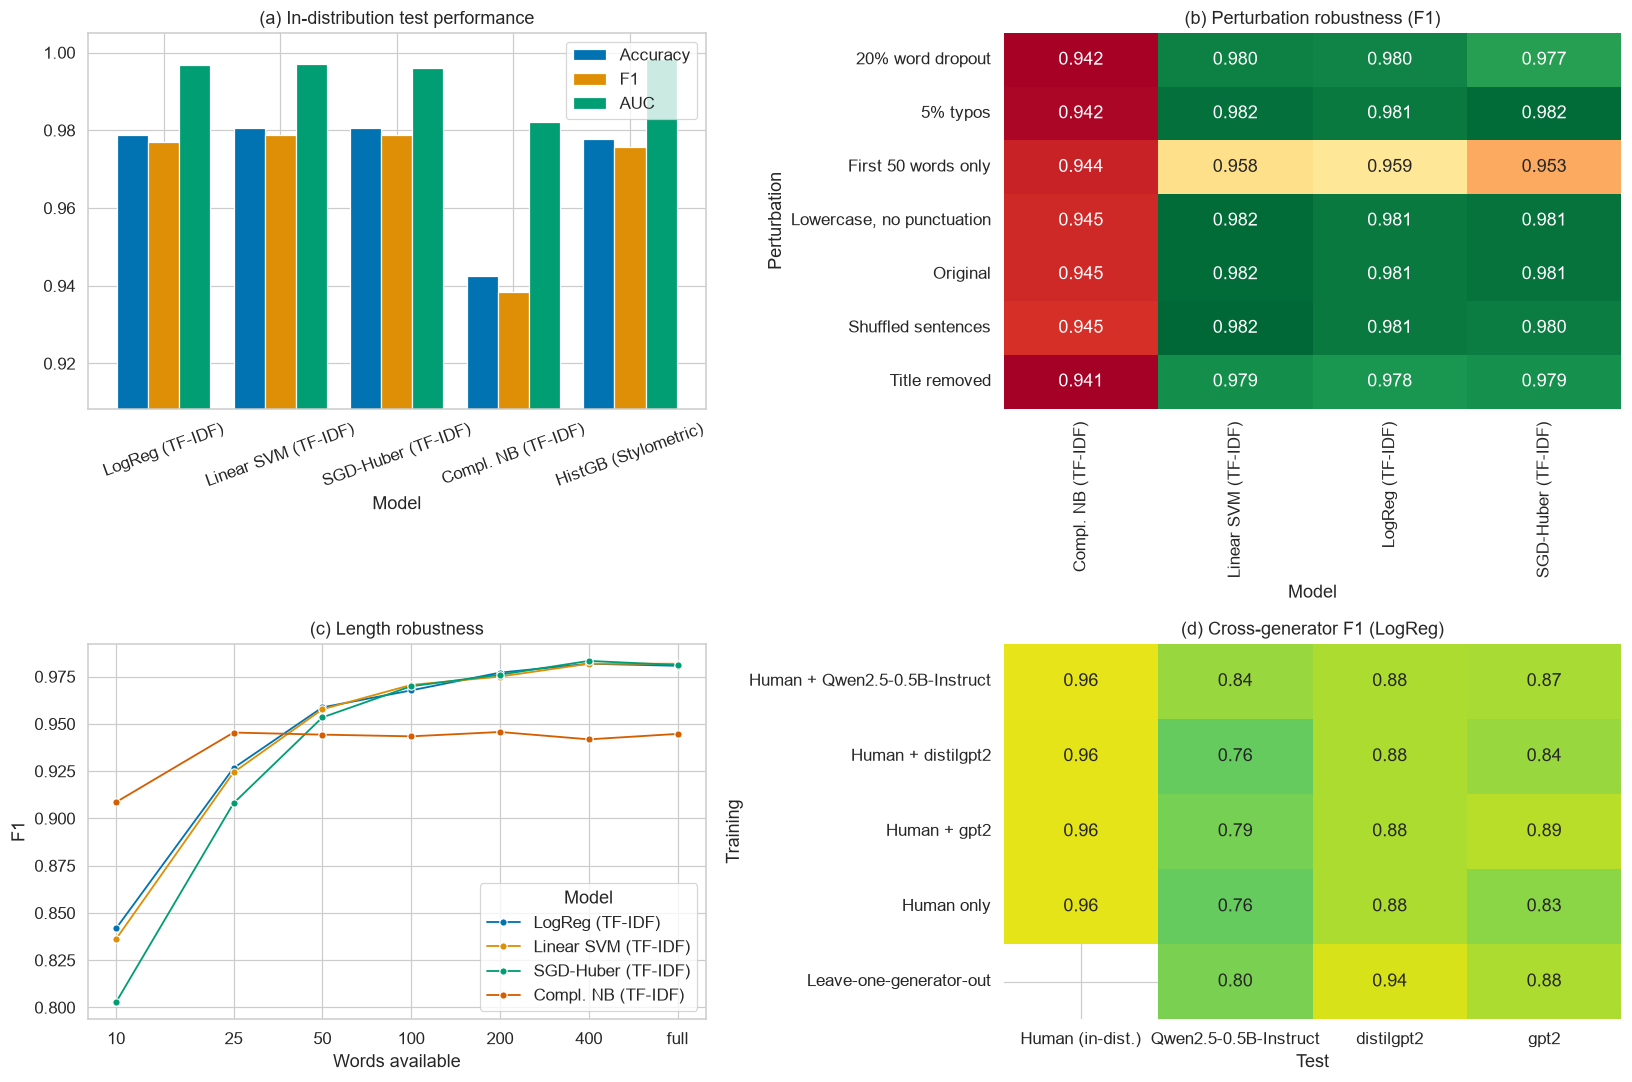

Best in-distribution detector: Linear SVM (TF-IDF) (test F1=0.979, AUC=0.997).
Largest perturbation drop: 'First 50 words only' (mean F1 0.954 vs 0.972 unperturbed).
Length: F1 0.847 with 10 words vs 0.972 with full text.
Zero-shot transfer to LLM fakes: mean F1=0.811, recall=0.705 (human in-dist. F1=0.961).
Leave-one-generator-out: mean F1=0.871 (+0.061 vs zero-shot).

✅ All done. Figures: outputs/figures | Tables (CSV + LaTeX): outputs/tables


In [9]:
T = OUT / "tables"; t3 = pd.read_csv(T / "t3_test_results.csv", index_col=0); t6 = pd.read_csv(T / "t6_perturbation_results.csv"); t7 = pd.read_csv(T / "t7_length_robustness.csv")
fig, ax = plt.subplots(2, 2, figsize=(15, 10))
t3[["Accuracy", "F1", "AUC"]].plot(kind="bar", ax=ax[0, 0], rot=20, width=.8); ax[0, 0].set_ylim(max(.5, float(t3[["Accuracy", "F1", "AUC"]].values.min()) - .03), 1.005); ax[0, 0].set_title("(a) In-distribution test performance")
sns.heatmap(t6.pivot(index="Perturbation", columns="Model", values="F1"), annot=True, fmt=".3f", cmap="RdYlGn", ax=ax[0, 1], cbar=False); ax[0, 1].set_title("(b) Perturbation robustness (F1)")
t7["x"] = t7.Words.map(lambda w: 800 if w == "full" else int(w)); sns.lineplot(data=t7, x="x", y="F1", hue="Model", marker="o", ax=ax[1, 0]); ax[1, 0].set_xscale("log")
ax[1, 0].set_xticks(sorted(t7.x.unique())); ax[1, 0].set_xticklabels([("full" if v == 800 else str(v)) for v in sorted(t7.x.unique())]); ax[1, 0].set_title("(c) Length robustness"); ax[1, 0].set_xlabel("Words available")
if len(cross):
    z = cross[cross.Model == "LogReg"]; sns.heatmap(z.pivot(index="Training", columns="Test", values="F1"), annot=True, fmt=".2f", cmap="viridis", vmin=0, vmax=1, ax=ax[1, 1], cbar=False); ax[1, 1].set_title("(d) Cross-generator F1 (LogReg)")
else: ax[1, 1].axis("off"); ax[1, 1].text(.5, .5, "(d) Cross-generator results\nappear after LLM text is generated", ha="center", va="center", fontsize=13)
plt.tight_layout(); savefig("fig9_paper_summary")

best = t3["F1"].idxmax(); L = [f"Best in-distribution detector: {best} (test F1={t3.loc[best, 'F1']:.3f}, AUC={t3.loc[best, 'AUC']:.3f}).",
     f"Largest perturbation drop: '{t6[t6.Perturbation != 'Original'].groupby('Perturbation').F1.mean().idxmin()}' "
     f"(mean F1 {t6[t6.Perturbation != 'Original'].groupby('Perturbation').F1.mean().min():.3f} vs {t6[t6.Perturbation == 'Original'].F1.mean():.3f} unperturbed).",
     f"Length: F1 {t7[t7.Words.astype(str) == '10'].F1.mean():.3f} with 10 words vs {t7[t7.Words.astype(str) == 'full'].F1.mean():.3f} with full text."]
if len(cross):
    z = cross[(cross.Training == "Human only") & (cross.Test != "Human (in-dist.)")]; h = cross[(cross.Training == "Human only") & (cross.Test == "Human (in-dist.)")].F1.mean()
    L.append(f"Zero-shot transfer to LLM fakes: mean F1={z.F1.mean():.3f}, recall={z.Recall.mean():.3f} (human in-dist. F1={h:.3f}).")
    if len(gens) >= 2: l = cross[cross.Training == "Leave-one-generator-out"]; L.append(f"Leave-one-generator-out: mean F1={l.F1.mean():.3f} ({l.F1.mean() - z.F1.mean():+.3f} vs zero-shot).")
print("\n".join(L)); (OUT / "key_findings.txt").write_text("\n".join(L))
print("\n✅ All done. Figures: outputs/figures | Tables (CSV + LaTeX): outputs/tables")